### Initial packages, etc

In [1]:
!wget https://storage.googleapis.com/magentadata/datasets/maestro/v3.0.0/maestro-v3.0.0-midi.zip
!unzip -q maestro-v3.0.0-midi.zip

--2026-10-15 18:39:35--  https://storage.googleapis.com/magentadata/datasets/maestro/v3.0.0/maestro-v3.0.0-midi.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 34.144.171.27, 34.144.170.27, 34.153.3.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|34.144.171.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58416533 (56M) [application/octet-stream]
Saving to: ‘maestro-v3.0.0-midi.zip.2’

maestro-v3.0.0-midi 100%[===================>]  55.71M  --.-KB/s    in 0.1s    

2026-10-15 18:39:35 (409 MB/s) - ‘maestro-v3.0.0-midi.zip.2’ saved [58416533/58416533]

replace maestro-v3.0.0/2004/MIDI-Unprocessed_XP_08_R1_2004_01-02_ORIG_MID--AUDIO_08_R1_2004_01_Track01_wav.midi? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [2]:
!apt-get update -qq
!apt-get install -y -qq fluidsynth fluid-soundfont-gm
!pip install -q pyfluidsynth pretty_midi

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1build1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1

In [3]:
import torch
import torch.nn as nn
import pretty_midi
from pathlib import Path
from tqdm import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'

### READING FILES AND TOKENIZE

In [4]:
files = sorted(Path("maestro-v3.0.0").rglob("*.midi"))
print(len(files))   # should be around 1,276
print(files[0])

1276
maestro-v3.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_05_Track05_wav.midi


In [5]:
"""
CALCULATE MIN AND MAX IF NECESSARY
MAX = 0
MIN = float('inf')

for file in tqdm(files):
    pm = pretty_midi.PrettyMIDI(str(file))
    piano = pm.instruments[0]
    for note in piano.notes:
        if MAX < note.pitch: MAX = note.pitch
        if MIN > note.pitch: MIN = note.pitch"""

"\nCALCULATE MIN AND MAX IF NECESSARY\nMAX = 0\nMIN = float('inf')\n\nfor file in tqdm(files):\n    pm = pretty_midi.PrettyMIDI(str(file))\n    piano = pm.instruments[0]\n    for note in piano.notes:\n        if MAX < note.pitch: MAX = note.pitch\n        if MIN > note.pitch: MIN = note.pitch"

In [6]:
MAX = 108
MIN = 21

In [7]:
import numpy as np
import torch

SCALE = 0.001
MAXTIME = 100
pieces = []

class Note():
    def __init__(self, pitch, time, timing):
        self.pitch = pitch
        self.time = int(round(time / SCALE))
        self.timing = timing

def make_tokens(file):
    j = k = 0
    notes = []
    pm = pretty_midi.PrettyMIDI(str(file))
    piano = next(inst for inst in pm.instruments if not inst.is_drum)
    for note in piano.notes:
            note_1 = Note(note.pitch, note.start, 'START')
            note_2 = Note(note.pitch, note.end, 'END')
            notes.append(note_1)
            notes.append(note_2)
    sorted_notes = sorted(notes, key=lambda x: x.time)

    final_notes = []
    for i in range(len(sorted_notes) - 1):
        final_notes.append((sorted_notes[i].timing, sorted_notes[i].pitch))
        time_step = sorted_notes[i+1].time - sorted_notes[i].time
        if time_step != 0:
            while time_step > MAXTIME:
                final_notes.append(('TIME', MAXTIME))
                time_step -= MAXTIME
            final_notes.append(('TIME', time_step))

    final_notes.append((sorted_notes[-1].timing, sorted_notes[-1].pitch))
    return final_notes

In [8]:
token_sqs = [make_tokens(file) for file in tqdm(files)]

100%|██████████| 1276/1276 [06:04<00:00,  3.50it/s]


In [9]:
token_sqs_lens = [len(token_sq) for token_sq in token_sqs]

MAX_PIECE = max(token_sqs_lens)
MIN_PIECE = min(token_sqs_lens)
MEAN_PIECE = sum(token_sqs_lens)/len(token_sqs_lens)

print(f"MAX: {MAX_PIECE} MIN: {MIN_PIECE} MEAN: {MEAN_PIECE} TOTAL TOKENS {sum(token_sqs_lens)}")

MAX: 109069 MIN: 853 MEAN: 24211.17789968652


In [10]:
def make_vocab():
    vocab = {'PAD': 0, 'BOS': 1, 'EOS': 2}
    for kind in ('START', 'END'):
        for p in range(MIN, MAX+1):
            vocab[(kind, p)] = len(vocab)
    for t in range(1, MAXTIME+1):
        vocab[('TIME', t)] = len(vocab)
    return vocab

def make_ids(tokens, vocab):
    ids = [vocab['BOS']]
    for key, val in tokens:
        ids.append(vocab[(key, val)])
    ids.append(vocab['EOS'])
    return ids

In [12]:
#CREATE VOCAB TOKEN -> IDS
vocab = make_vocab()
vocab_size = len(vocab)

### CREATING THE DATA TENSOR

In [51]:
from torch.utils.data import Dataset, DataLoader
import random
#CREATING THE TENSOR
class MidiDataset(Dataset):
    def __init__(self, tokens, sq_len, dataset_len, vocab):
        self.ids = [torch.tensor(make_ids(sq, vocab), dtype=torch.long) for sq in tokens]
        self.len = dataset_len
        self.sq_len = sq_len

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        sq = random.choice(self.ids)
        idx = random.randint(0, max(0, len(sq) - self.sq_len))
        sq = sq[idx:idx+self.sq_len]
        sq = torch.nn.functional.pad(sq, (0, self.sq_len - len(sq)), value=0)
        return sq

def make_xy(samples):
    samples = torch.stack(samples)
    return samples[..., :-1], samples[..., 1:]

In [52]:
n = 0.9
sq_len = 1024
dataset_len_train = 5000
dataset_len_test = 500

token_sqs_train = token_sqs[:int(len(token_sqs)*n)]
token_sqs_test = token_sqs[int(len(token_sqs)*n):]

data_train = MidiDataset(
    tokens=token_sqs_train,
    sq_len=sq_len,
    dataset_len=dataset_len_train,
    vocab=vocab
    )

data_test = MidiDataset(
    tokens=token_sqs_test,
    sq_len=sq_len,
    dataset_len=dataset_len_test,
    vocab=vocab
    )

data_train_loader = DataLoader(data_train, batch_size=16, shuffle=True, collate_fn=make_xy)
data_test_loader = DataLoader(data_test, batch_size=16, shuffle=False, collate_fn=make_xy)

### TRAIN TEST FUNC

In [50]:
def train_and_test(model, loss_fn, optimizer, epochs, dataloader_train, dataloader_test):
    loss_list = []
    loss_test_list = []
    for epoch in tqdm(range(epochs)):
        loss_epoch = training(model, loss_fn, optimizer, epochs, dataloader_train)
        loss_list.append(loss_epoch)
        loss_test_epoch = testing(model, loss_fn, epochs, dataloader_test)
        loss_test_list.append(loss_test_epoch)
        print(f"\nTRAIN LOSS {loss_epoch} TEST LOSS {loss_test_epoch}")
    return (loss_list, loss_test_list)

def training(model, loss_fn, optimizer, epochs, dataloader):
    model.train()
    loss_epoch = 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        B, N = yb.shape
        yb = yb.reshape(B*N)
        y_pred = model(xb)
        loss = loss_fn(y_pred, yb)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        loss_epoch += loss.item()
    return loss_epoch/len(dataloader)

@torch.no_grad()
def testing(model, loss_fn, epochs, dataloader):
    model.eval()
    loss_epoch = 0
    for xb, yb in dataloader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        B, N = yb.shape
        yb = yb.reshape(B*N)
        y_pred = model(xb)
        loss = loss_fn(y_pred, yb)
        loss_epoch += loss.item()
    return loss_epoch/len(dataloader)

import matplotlib.pyplot as plt

def plot_loss(loss):
    plt.plot(loss[0], label="train")
    plt.plot(loss[1], label="test")
    plt.legend()
    print(loss[-1])

### AUDIO GENERATION

In [16]:
from IPython.display import Audio, display

@torch.no_grad()
def generate_bigrammodel(bigrammodel, max_tokens, idx=1): #idx=1=BOS
    bigrammodel = bigrammodel.to('cpu')
    sq = [idx]
    for _ in range(max_tokens):
        idx = torch.tensor(idx, dtype=torch.long).unsqueeze(dim=-1).unsqueeze(dim=-1)
        logits = bigrammodel(idx)
        logits = logits
        probs = nn.functional.softmax(logits, dim=-1)
        idx = torch.multinomial(probs, num_samples = 1).item()
        sq.append(idx)
    return sq

@torch.no_grad()
def generate_selfattention(model, max_tokens, idx=1):
    sq_res = [idx]
    i  = -sq_len
    for _ in range(max_tokens):
        sq = sq_res[-sq_len:] if len(sq_res) > sq_len else sq_res
        idx = torch.tensor(sq, dtype=torch.long).unsqueeze(dim=0).to(device)
        logits = model(idx)
        logits = logits[-1]
        probs = nn.functional.softmax(logits, dim=-1)
        idx = torch.multinomial(probs, num_samples = 1).item()
        sq_res.append(idx)
    return sq_res

def ids_to_tokens(ids, vocab):
    inv = {v: k for k, v in vocab.items()}
    tokens = []
    for i in ids:
        tok = inv[int(i)]
        if tok in ('PAD', 'BOS'):
            continue
        if tok == 'EOS':
            break
        tokens.append(tok)
    return tokens

def tokens_to_midi(tokens, scale, path='out.mid', velocity=80):
    pm = pretty_midi.PrettyMIDI()
    inst = pretty_midi.Instrument(program=0)
    t = 0                                # clock, in quantized ticks
    active = {}                          # pitch -> start tick

    def close(pitch, end_tick):
        start = active.pop(pitch)
        if end_tick > start:             # skip zero-length notes
            inst.notes.append(pretty_midi.Note(
                velocity=velocity, pitch=pitch,
                start=start * scale, end=end_tick * scale))

    for kind, val in tokens:
        if kind == 'TIME':
            t += val
        elif kind == 'START':
            if val in active:            # same pitch already sounding
                close(val, t)
            active[val] = t
        elif kind == 'END':
            if val in active:            # ignore ENDs with no matching START
                close(val, t)

    for pitch in list(active):           # close notes left hanging at the end
        close(pitch, t)

    pm.instruments.append(inst)
    pm.write(path)
    return pm

def make_audio(pm):
    sf2 = "/usr/share/sounds/sf2/FluidR3_GM.sf2"
    audio = pm.fluidsynth(fs=44100, sf2_path=sf2)
    display(Audio(audio, rate=44100))

def ids_to_audio(ids, vocab=vocab, scale=SCALE, path='out.mid', velocity=80):
    tokens = ids_to_tokens(ids, vocab)
    pm = tokens_to_midi(tokens, scale, path, velocity)
    make_audio(pm)

### BIGRAM MODEL

In [ ]:
import torch.nn as nn
torch.manual_seed(1502)

class BigramModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx):
        logits = self.token_embedding_table(idx)
        B, N, L = logits.shape #Inside each batch, each note is now a list of logits
        logits = logits.reshape(B*N, L)
        return logits

In [ ]:
m = BigramModel(vocab_size)
m = m.to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=m.parameters(), lr=1e-3)

for epoch in tqdm(range(100)):
    for xb, yb in data_train_loader:

        B, N = yb.shape
        yb = yb.reshape(B*N)

        y_pred = m(xb)
        loss = loss_fn(y_pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
print(loss.item())

100%|██████████| 100/100 [00:06<00:00, 14.96it/s]

3.589205503463745


### SLEF ATTENTION

In [53]:
import torch.nn as nn
torch.manual_seed(1502)
n_embed = 384
dropout=0.2


class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embed, head_size, bias=False)
        self.query = nn.Linear(n_embed, head_size, bias=False)
        self.value = nn.Linear(n_embed, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(sq_len, sq_len)))

    def forward(self, x):
        B,T,N = x.shape #B, T, N_EMBED
        k = self.key(x)   # (B,T,H)
        q = self.query(x) # (B,T,H)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * N**-0.5 # (B, T, H) @ (B, H, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = nn.functional.softmax(wei, dim=-1) # (B, T, T)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,H)
        out = wei @ v # (B, T, T) @ (B, T, H) -> (B, T, H)
        return out

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embed, n_embed)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = torch.cat([h(x) for h in self.heads], dim=-1)
        x = self.proj(x)
        x = self.dropout(x)
        return x

class FeedFoward(nn.Module):
    def __init__(self, n_embed):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embed, 4 * n_embed),
            nn.ReLU(),
            nn.Linear(4 * n_embed, n_embed),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class BigramModel2(nn.Module):
    def __init__(self, vocab_size, n_layer=4, n_head=8):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embed)
        self.position_embedding_table = nn.Embedding(sq_len, n_embed)
        self.blocks = nn.Sequential(*[Block(n_embed, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embed) # final layer norm
        self.lm_head = nn.Linear(n_embed, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        token_embed = self.token_embedding_table(idx) #B, T, N_EMBED
        pos_embed = self.position_embedding_table(torch.arange(T, device=device)) #T, C is the same for every batch
        x = token_embed + pos_embed
        x = self.blocks(x) # (B,T,N)
        x = self.ln_f(x) # (B,T,N)
        logits = self.lm_head(x) # (B,T,vocab_size)

        B, T, L = logits.shape #BATCH, TOKEN, LOGIT
        logits = logits.reshape(B*T, L)
        return logits

In [54]:
m = BigramModel2(vocab_size).to(device)

In [58]:
loss_fn = nn.CrossEntropyLoss(ignore_index=0)
optimizer = torch.optim.Adam(params=m.parameters(), lr=1e-3)
epochs = 10
loss = train_and_test(
    model=m,
    loss_fn=loss_fn,
    optimizer=optimizer,
    epochs=epochs,
    dataloader_train=data_train_loader,
    dataloader_test=data_test_loader)

 10%|█         | 1/10 [00:49<07:23, 49.27s/it]


TRAIN LOSS 2.838879924231825 TEST LOSS 2.777803346514702


 20%|██        | 2/10 [01:38<06:34, 49.26s/it]


TRAIN LOSS 2.830726006541389 TEST LOSS 2.807639591395855


 30%|███       | 3/10 [02:27<05:44, 49.26s/it]

...


TRAIN LOSS 2.8020816214930133 TEST LOSS 2.7770156413316727


 90%|█████████ | 9/10 [07:23<00:49, 49.26s/it]


TRAIN LOSS 2.7902392800242755 TEST LOSS 2.7688173577189445


100%|██████████| 10/10 [08:12<00:00, 49.26s/it]


TRAIN LOSS 2.792702936135923 TEST LOSS 2.7600881159305573


[2.777803346514702, 2.807639591395855, 2.8087542727589607, 2.7771714702248573, 2.778624229133129, 2.7870889082551003, 2.7792734429240227, 2.7770156413316727, 2.7688173577189445, 2.7600881159305573]


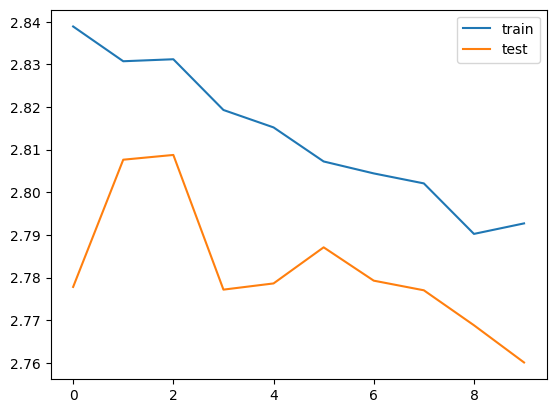

In [59]:
plot_loss(loss)

In [62]:
ids = generate_selfattention(model=m, max_tokens=2000)
tokens = ids_to_tokens(ids, vocab)
pm = tokens_to_midi(tokens, scale=SCALE)
make_audio(pm)

/tmp/ipykernel_2949/1422006681.py:75: DeprecationWarning: The parameter 'sf2_path' is deprecated, please use 'synthesizer' instead.
  audio = pm.fluidsynth(fs=44100, sf2_path=sf2)


To fix: